In [ ]:
# Import libaries:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [ ]:
#Import Libaries w/ APIs:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

In [ ]:
# Ignore warnings:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Mount Google Drive to access your files
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/drive/My Drive/Chest-X-Ray-Pneumonia/archive/chest_xray
!ls -a


/content/drive/My Drive/Chest-X-Ray-Pneumonia/archive/chest_xray
.  ..  chest_xray  __MACOSX  test  train  val


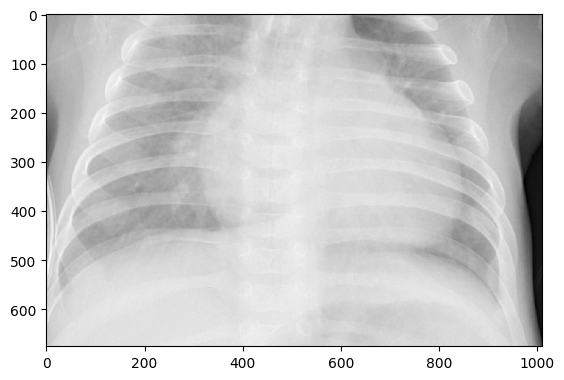

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

!pip install opencv-python

# Update DATADIR to reflect the path in your Google Drive
# Make sure to upload your 'kagglecatsanddogs_5340' folder to your Google Drive
DATADIR = "/content/drive/My Drive/Chest-X-Ray-Pneumonia/archive/chest_xray/train"
CATEGORIES = ["PNEUMONIA", "NORMAL"]

for category in CATEGORIES:
  path = os.path.join(DATADIR, category) #path to cats or dogs

  for img in os.listdir(path):
    img_array = cv2.imread(os.path.join(path,img), cv2.IMREAD_GRAYSCALE)
    plt.imshow(img_array, cmap='gray')
    plt.show()
    break
  break

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define directories based on the extracted dataset
train_dir = "/content/drive/My Drive/Chest-X-Ray-Pneumonia/archive/chest_xray/train"
val_dir = "/content/drive/My Drive/Chest-X-Ray-Pneumonia/archive/chest_xray/val"
test_dir = "/content/drive/My Drive/Chest-X-Ray-Pneumonia/archive/chest_xray/test"

# Augmentation and Normalization
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

# Load generators
batch_size = 32
img_size = (224, 224)

train_generator = train_datagen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size, class_mode='binary'
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir, target_size=img_size, batch_size=batch_size, class_mode='binary'
)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


In [ ]:
#Importing DenseNet using TensorFlow / Keras

from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model

# 1. Load the base DenseNet-121 model pre-trained on ImageNet
base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# 2. Add custom layers for Pneumonia classification
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)

# Binary classification (Pneumonia vs Normal)
predictions = Dense(1, activation='sigmoid')(x)

# 3. Create the final model
model = Model(inputs=base_model.input, outputs=predictions)

# 4. Freeze base layers so pre-trained weights aren't updated during early training
for layer in base_model.layers:
    layer.trainable = False

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
import tensorflow as tf

# Check if GPU is available
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

# Print the name of the GPU device
if tf.config.list_physical_devices('GPU'):
    print("GPU Device Name:", tf.test.gpu_device_name())
else:
    print("Please switch your runtime to GPU.")


Num GPUs Available:  1
GPU Device Name: /device:GPU:0


In [ ]:
# Initial Training
from tensorflow.keras.optimizers import Adam
model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

# Optional: Fine-tuning by unfreezing the last 20 layers
for layer in base_model.layers[-20:]:
    layer.trainable = True

# Recompile with a lower learning rate for fine-tuning
model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])

# Continue Training
history_fine = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 1441s 9s/step - accuracy: 0.9199 - loss: 0.1994 - val_accuracy: 0.8750 - val_loss: 0.1713
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 134s 819ms/step - accuracy: 0.9448 - loss: 0.1341 - val_accuracy: 0.9375 - val_loss: 0.2026
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 138s 844ms/step - accuracy: 0.9434 - loss: 0.1465 - val_accuracy: 0.9375 - val_loss: 0.1465
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 139s 853ms/step - accuracy: 0.9492 - loss: 0.1249 - val_accuracy: 0.8750 - val_loss: 0.2114
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 144s 884ms/step - accuracy: 0.9528 - loss: 0.1201 - val_accuracy: 0.9375 - val_loss: 0.2150
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 139s 854ms/step - accuracy: 0.9534 - loss: 0.1154 - val_accuracy: 0.9375 - val_loss: 0.1915
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 146s 893ms/step - accuracy: 0.9597 - loss: 0.1045 - val_accuracy: 0.9375 - val_loss: 0.1694
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 144s 881ms/step - accuracy: 0.9628 - l

## Model Evaluation and Training History Visualization

In [ ]:
# Prepare the test generator
test_generator = val_test_datagen.flow_from_directory(
    test_dir, target_size=img_size, batch_size=batch_size, class_mode='binary', shuffle=False
)

# Evaluate the model on the test set
print("\nEvaluating model on the test set...")
loss, accuracy = model.evaluate(test_generator)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Found 624 images belonging to 2 classes.

Evaluating model on the test set...
20/20 ━━━━━━━━━━━━━━━━━━━━ 145s 7s/step - accuracy: 0.8958 - loss: 0.3892
Test Loss: 0.3892
Test Accuracy: 0.8958


### Visualize Training History
Plotting the training and validation accuracy and loss curves to see how the model performed during the initial training and fine-tuning phases

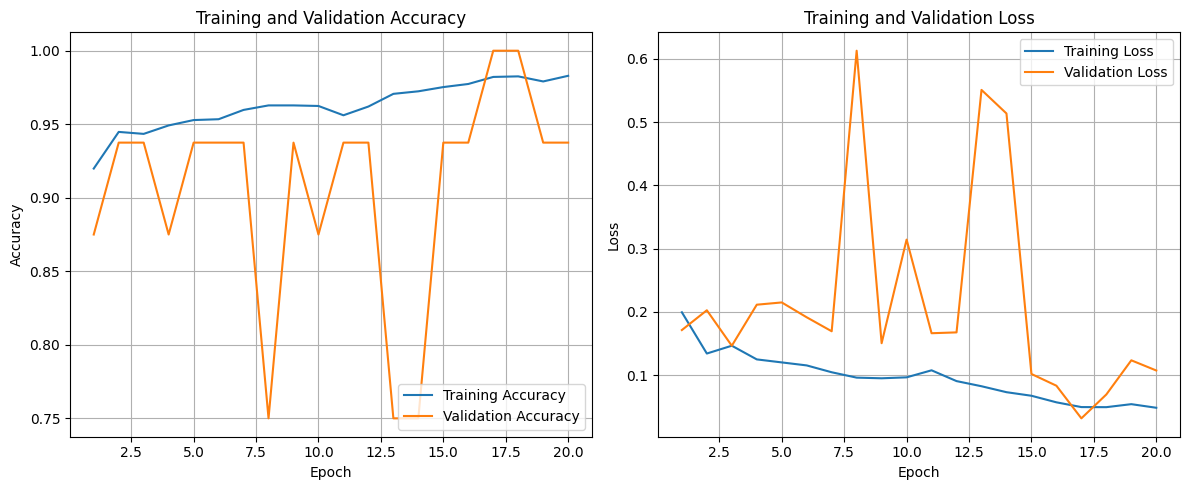

In [ ]:
import matplotlib.pyplot as plt

# Combine history objects for plotting
hist_df = history.history
hist_fine_df = history_fine.history

# Create combined history dictionaries
combined_history = {}
for key in hist_df.keys():
    combined_history[key] = hist_df[key] + hist_fine_df[key]

epochs_range = range(1, len(combined_history['accuracy']) + 1)

plt.figure(figsize=(12, 5))

# Plot Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, combined_history['accuracy'], label='Training Accuracy')
plt.plot(epochs_range, combined_history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, combined_history['loss'], label='Training Loss')
plt.plot(epochs_range, combined_history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

### Confusion Matrix
To understand the model's performance in terms of true positives, true negatives, false positives, and false negatives

Generating predictions for the test set...
20/20 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step


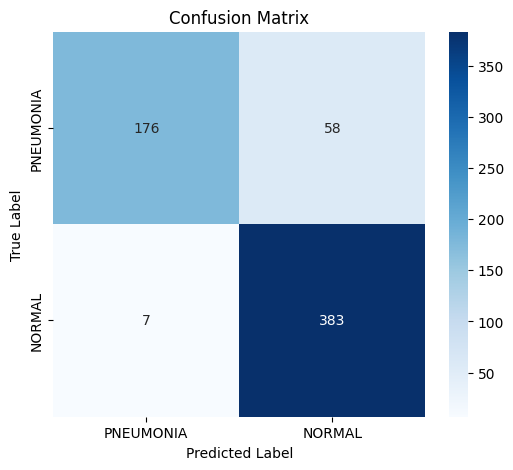

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

# Get predictions on the test set
print("Generating predictions for the test set...")
predictions = model.predict(test_generator)

# Convert probabilities to binary class labels (0 or 1)
y_pred = np.round(predictions).flatten()

# Get true labels from the test generator
y_true = test_generator.classes

# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CATEGORIES, yticklabels=CATEGORIES)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

###Seeing results based on the individual image

In [ ]:
import os
import cv2
import numpy as np

CATEGORIES = ["PNEUMONIA", "NORMAL"]
DATADIR = "/content/drive/My Drive/Chest-X-Ray-Pneumonia/archive/chest_xray/test"

# Define the prepare function to preprocess the image for the model
def prepare(filepath):
    IMG_SIZE = 224  # Model expects 224x224 images

    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Image file not found at: {filepath}")

    # Load image as color (3 channels) as the DenseNet model expects 3 channels
    img_array = cv2.imread(filepath, cv2.IMREAD_COLOR)

    if img_array is None:
        raise IOError(f"Could not load image from: {filepath}. It might be corrupted or an invalid format.")

    new_array = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
    # Reshape to 4D array: (batch_size, IMG_SIZE, IMG_SIZE, 3)
    return new_array.reshape(-1, IMG_SIZE, IMG_SIZE, 3)


In [ ]:
# Construct the full path to the image
image_path = os.path.join(DATADIR, 'pneumoniatest.jpeg')

# Make a prediction
prediction = model.predict(prepare(image_path))
print(CATEGORIES[int(prediction[0][0])])

# Construct the full path to the image
image_path = os.path.join(DATADIR, 'normaltest.jpeg')

# Make a prediction
prediction = model.predict(prepare(image_path))
print(CATEGORIES[int(prediction[0][0])])

# Construct the full path to the image
image_path = os.path.join(DATADIR, 'ridhimap.jpeg')

# Make a prediction
prediction = model.predict(prepare(image_path))
print(CATEGORIES[int(prediction[0][0])])


